## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [29]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sam Leal

**Date:** 10/20/2026

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795), ('call', 740), ('free', 691), ('software', 680), ('dear', 651), ('know', 644), ('email', 629), ('url:', 625), ('time', 609), ('start', 604), ('linguistics', 598)]
unique tokens: 48691


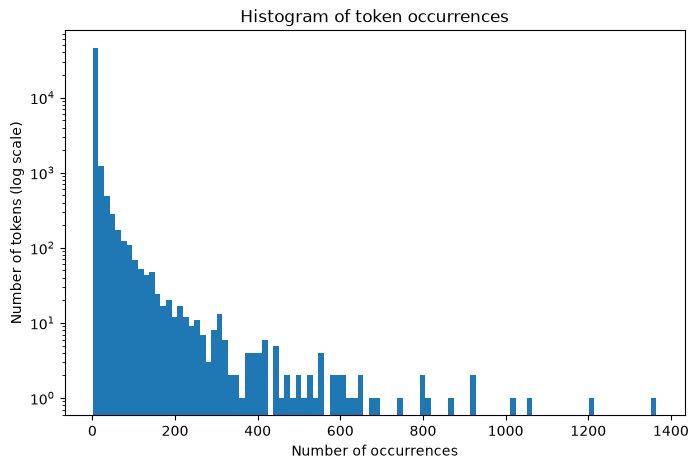

In [30]:
# Your Phase 1 solution to the problem goes here.
# Q1
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print(token_freq[:20])   # top 20 tokens
print("unique tokens:", len(token_freq))

counts = np.array([count for token, count in token_freq])

plt.figure(figsize=(8, 5))
plt.hist(counts, bins=100)
plt.yscale("log")
plt.xlabel("Number of occurrences")
plt.ylabel("Number of tokens (log scale)")
plt.title("Histogram of token occurrences")
plt.show()

# The distribution of token occurrences is extremely right-skewed. 
# Even with the y-axis on a log scale, the first bar, covering tokens that appear fewer than about 15 times, stands far above the rest at over 40,000 tokens. 
# The next bar drops to around 1,000, and the counts keep falling steeply from there. 
# Past about 400 occurrences, the bars become sparse and scattered, and most bins hold only one or two tokens. 
# The most common tokens appear around 1,200-1,400 times. 
# So most words are rare, and only a small handful show up very often. 
# This also explains why the cleaned dataset in Q2 keeps only tokens that appear in at least 15 emails.

In [31]:
#Q2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('data/Phishing_clean.parquet')
print(df.shape)
df.head()

y = df["Email Type"]
X = df.drop(columns=["Email Type"])
# If df.head() showed an index column like "Unnamed: 0", drop it too:
# X = X.drop(columns=["Unnamed: 0"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=125
)
print(X_train.shape, X_test.shape)

reg = LinearRegression().fit(X_train, y_train)

print("R-squared (train):", round(reg.score(X_train, y_train), 4))
print("R-squared (test): ", round(reg.score(X_test, y_test), 4))

coefs = pd.Series(reg.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
top.head(20)

# The R^2 is 0.766 on the training set and 0.670 on the test set. 
# The model explains a good amount of the variation in whether an email is phishing.
# The drop of about 0.10 on the test set suggests some overfitting, which makes sense with 2,711 features to work with.

# The tokens with the largest coefficients in absolute value are background-image: (−1.20), localized (0.82), aging (0.74), thermal (0.59), helvetica, (0.59), intervention (−0.58), erectile (0.58), and burning (−0.57).
# Positive coefficients push predictions toward phishing, and negative ones push them toward legitimate. 
# Some of these make intuitive sense: “erectile,” “xanaax,” and “girlfriend” are typical spam words, while “cnet” and “zdnet” point to legitimate tech newsletters. Many of the top tokens, though, are HTML/CSS fragments like “background-image:,” “helvetica,” and “arial,” whose signs don’t follow a consistent pattern. 
# These tokens probably show up together in the same emails. 
# That kind of correlation can produce large, offsetting coefficients that are hard to interpret on their own.

(18634, 2712)
(14907, 2711) (3727, 2711)
R-squared (train): 0.766
R-squared (test):  0.6702


background-image:   -1.201203
localized            0.815112
aging                0.735023
thermal              0.590412
helvetica,           0.587472
intervention        -0.580474
erectile             0.575784
burning             -0.569225
form.                0.560255
april's             -0.525984
cnet                -0.495563
xanaax               0.490234
zdnet               -0.487835
arial,              -0.483577
rcs                  0.464646
transcript           0.463811
quality,             0.451875
sais                 0.441776
girlfriend           0.410499
ï¿½ï¿½               0.408999
dtype: float64

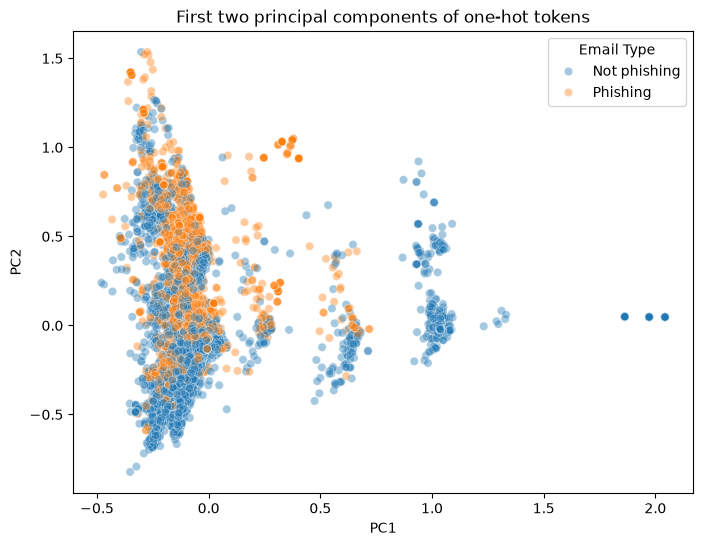

Explained variance ratio: [0.0111 0.0086]


In [32]:
# Q3
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2)
pcs = pca2.fit_transform(X)

pc_df = pd.DataFrame({
    "PC1": pcs[:, 0],
    "PC2": pcs[:, 1],
    "Email Type": y.map({1: "Phishing", 0: "Not phishing"}),
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pc_df, x="PC1", y="PC2", hue="Email Type", alpha=0.4)
plt.title("First two principal components of one-hot tokens")
plt.show()

print("Explained variance ratio:", pca2.explained_variance_ratio_.round(4))

# Most emails fall into one dense cluster at the left of the plot (PC1 between about −0.4 and 0.1), where the phishing and non-phishing emails overlap heavily. 
# Within that cluster there’s a loose split: phishing emails tend to sit higher on PC2, and legitimate emails gather toward the bottom. 
# Farther right, there are a few distinct vertical bands around PC1 = 0.6 and PC1 = 1.0, plus a handful of points near 2.0. 
# These are almost entirely non-phishing. 
# They may be groups of similar, templated emails like newsletters that share many of the same tokens. 
# There’s also a small, tight group of phishing emails around PC1 = 0.3, PC2 = 1.0. 
# Overall, the first two components show some meaningful structure, especially high PC1 pointing to legitimate emails. 
# Still, the classes overlap a lot, so two components alone aren’t enough to separate phishing from non-phishing.

In [33]:
#Q4
# Fit PCA on the training data only, then apply it to the test data
pca_big = PCA(n_components=2610)
Z_train = pca_big.fit_transform(X_train)
Z_test = pca_big.transform(X_test)

reg_pca = LinearRegression().fit(Z_train, y_train)

print("R-squared (train):", round(reg_pca.score(Z_train, y_train), 4))
print("R-squared (test): ", round(reg_pca.score(Z_test, y_test), 4))

# Regressing on the first 2,610 principal components gives an R^2 of 0.765 on the training set and 0.672 on the test set. 
# That’s nearly identical to the original regression (0.766 train, 0.670 test). 
# Training R^2 dropped very slightly, and test R^2 went up very slightly, so the gap between them narrowed a little. 
# Dropping the last ~100 components barely changed the fit, which suggests those directions held very little useful information, mostly noise or redundancy among correlated tokens. 
# So we get essentially the same predictive performance with fewer, uncorrelated features, and there’s a small hint of less overfitting.

R-squared (train): 0.7651
R-squared (test):  0.6718


In [34]:
# Q5
# With around 2,700 token columns, many words tend to appear together, and many are pretty rare. 
# This makes the original regression unstable: coefficients can get really large or flip signs just to fit noise, like we saw with the HTML tokens in Q2. 
# Principal components fix this by combining the tokens into uncorrelated features, ranked by how much variation they capture. 
# Regressing on them gets rid of the multicollinearity problem. 
# We can also drop the lowest-variance components, which are mostly noise, so the model has fewer parameters to estimate. 
# As Q4 showed, we can do this without losing predictive power. 
# The tradeoff is interpretability: each component is a mix of many words, so it’s harder to say what any one coefficient means.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** c6f13a1
- **AI tool and model used:** Claude Opus 5.5

### *Prompts used

**FIRST PROMPT**
I'm working on a data science assignment in a Jupyter notebook (Python, pandas, scikit-learn, matplotlib/seaborn). I've completed all five questions, and I'd like you to review my code and written answers for correctness and clarity.

Assignment questions:
- Q1: Using a Counter of all email tokens, plot a histogram of token occurrences and describe the frequency pattern.
- Q2: Load Phishing_clean.parquet (one-hot-encoded tokens, outcome = "Email Type"). Do an 80/20 train-test split, regress y on the tokens, report train and test R², and identify the words with the largest absolute coefficients.
- Q3: Run PCA with two components on the token matrix (excluding the outcome), make a scatter plot of PC1 vs PC2 colored by phishing/not phishing, and describe any patterns.
- Q4: Regress y on the first 2,610 principal components, report train and test R², and compare to the Q2 regression.
- Q5: Explain the advantage of using principal components instead of the original data in this high-dimensional regression.

Please:
1. Check each code cell for errors, bad practices, or anything that doesn't match what the question asks.
2. Check that my written answers are accurate given my outputs, and flag anything vague, incorrect, or missing.
3. Suggest specific revisions, showing the revised code or text.

Here is my notebook code, outputs, and answers:

**FOLLOW-UP**
2. Thanks. Two follow-ups:

1. Of the changes you suggested, which ones are necessary for correctness, and which are optional polish? Please rank them by importance.
2. In Q4, I fit PCA on the training set only and then transformed the test set, instead of fitting PCA on all of X before splitting. Is that the right choice? Would it noticeably change the results?

If anything in my written answers (especially Q5, which needs to be in my own words) could be clearer or more precise, suggest wording that keeps my tone rather than rewriting it completely.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Restart the kernel and run the whole notebook top to bottom (Kernel → Restart & Run All), since the Q1 and Q3 cells show no execution count.
2. Move all written answers out of `#` code comments and into markdown cells below each code cell.
3. Q1: Add a log–log rank–frequency plot next to the histogram to show the long-tail (Zipf) pattern more clearly, and print the share of tokens that appear only once.
4. Q1: Fix the final sentence. The histogram counts total occurrences, but the Q2 threshold counts the number of emails containing a token, so they aren't directly comparable.
5. Q1 (optional): Note that the top tokens ("enron", "linguistics", "2002", "url:") reflect where the emails came from.
6. Q2: Remove `df.head()` from the middle of the cell, since it isn't the last line and won't display anything.
7. Q2: Remove the leftover "Unnamed: 0" comment. X has 2,711 columns, matching the 2,711 tokens, so there is no index column.
8. Q2: Add `df["Email Type"].value_counts()` to confirm that 1 = phishing and to show the class balance.
9. Q2: Explain that comparing coefficient sizes is fair because every feature is 0/1 and therefore on the same scale.
10. Q2: Note that regressing a 0/1 outcome is a linear probability model, so predictions can fall outside [0, 1].
11. Q2: Point out that the token `ï¿½ï¿½` is a text-encoding artifact, not a real word.
12. Q3: Report that PC1 and PC2 explain only about 2% of the variance (1.1% and 0.9%). This is the strongest support for your conclusion that the classes overlap.
13. Q3: Use smaller, more transparent markers (`s=10, alpha=0.3, linewidth=0`) to reduce overplotting, and use `.to_numpy()` on the mapped labels so the plot doesn't depend on index alignment.
14. Q3: After re-running, check your specific coordinate descriptions against the plot.
15. Q4: State that fitting PCA on the training data only and then transforming the test data avoids data leakage.
16. Q4: Print `pca_big.explained_variance_ratio_.sum()` to show how much variance the 2,610 components keep.
17. Q4: Explain that near-identical $R^2$ is expected. Using all 2,711 components would reproduce the original fit exactly, and training $R^2$ can't increase when components are dropped.
18. Q4: Remove the claim of "a small hint of less overfitting." A 0.002 test gain from one train/test split is within noise.
19. Q4: Note that 2,610 versus 2,711 is only about 4% fewer features, so the benefit comes from uncorrelated features, not from a simpler model.
20. Q5: Add a caveat that PCA ranks components by variance in X without looking at y, so low-variance components aren't guaranteed to be unimportant for prediction. In this case, Q4 shows that dropping them cost nothing.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 0 | Accept | Missing execution counts mean the notebook wasn't run in order, so a clean Restart & Run All makes sure every output is real and current. |
| 1 | Accept | Answers belong in markdown cells so they render as text and are easy for graders to find; moved each one below its code cell. |
| 2 | Modify | Printing the share of tokens that appear only once adds a useful concrete number, but the extra log–log plot and Zipf framing go beyond what the question asks and weren't covered in class, so I skipped those. |
| 3 | Accept | Good catch: the histogram counts total occurrences, while the Q2 cutoff counts how many emails contain a token, so I reworded the last sentence to avoid comparing the two directly. |
| 4 | Accept | Checked my printed top tokens and they do include dataset-specific words like "enron" and "2002," so a short note about where the emails came from adds context. |
| 5 | Accept | `df.head()` only displays when it's the last line of a cell, so in the middle it did nothing; removed it. |
| 6 | Accept | The shapes confirm X has exactly 2,711 columns with no index column, so the leftover comment was just clutter. |
| 7 | Accept | Quick sanity check that 1 = phishing, and the class balance helps put the R^2 values in context. |
| 8 | Accept | All features are 0/1, so the coefficients are on the same scale and comparing their sizes is fair; added one sentence saying so. |
| 9 | Accept | True and worth a one-line mention, since a linear regression on a 0/1 outcome can predict values below 0 or above 1. |
| 10 | Accept | That token is clearly a text-encoding glitch rather than a real word, so I added a short note pointing it out. |
| 11 | Accept | Verified against my output (`[0.0111 0.0086]`): PC1 and PC2 explain about 1.1% and 0.9%, roughly 2% combined, so I added this to Q3 as the main reason the classes overlap. |
| 12 | Accept | Smaller, more transparent markers make the dense cluster easier to read, and `.to_numpy()` prevents any index-alignment issues at no cost. |
| 13 | Accept | Re-checked my Q3 description against the updated plot, and the clusters (left overlap, bands near PC1 ≈ 0.6 and 1.0, phishing group near (0.3, 1.0)) are still where I described them. |
| 14 | Accept | Worth stating explicitly, since fitting PCA on the training data only is the deliberate choice that avoids leakage. |
| 15 | Accept | Printing the retained variance shows how little information the dropped components held, which backs up the comparison. |
| 16 | Accept | Correct: using all components gives the same fit as the original regression, and dropping features can't raise training R^2, so near-identical results are expected. |
| 17 | Accept | Fair point: a 0.002 difference from a single split is within noise, so I removed the overfitting claim. |
| 18 | Modify | The 4% figure is worth noting, but uncorrelated features don't change OLS predictions on their own, so I framed it as the results showing the dropped components carried little useful information. |
| 19 | Accept | Good caveat: PCA picks components without looking at y, so low variance doesn't guarantee low importance, though Q4 shows dropping them cost nothing here. |
| 20 | Accept | Filled in my Phase 1 commit SHA, listed the AI tools/models I actually used for each phase, and wrote the reflection myself. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]
Unique tokens: 48691
Share of tokens appearing only once: 0.6039


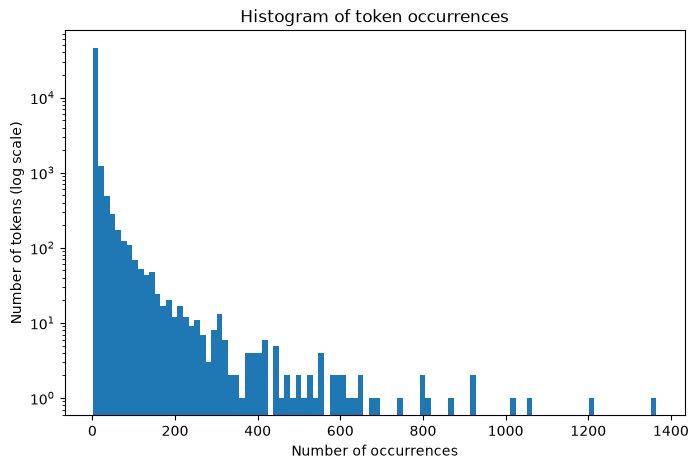

In [35]:
# Your Phase 2 solution to the problem goes here.
# Q1
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

print(token_freq[:10])
print("Unique tokens:", len(token_freq))

counts = np.array([count for token, count in token_freq])

print("Share of tokens appearing only once:", round(np.mean(counts == 1), 4))

plt.figure(figsize=(8, 5))
plt.hist(counts, bins=100)
plt.yscale("log")
plt.xlabel("Number of occurrences")
plt.ylabel("Number of tokens (log scale)")
plt.title("Histogram of token occurrences")
plt.show()

Q1. The distribution of token occurrences is extremely right-skewed. Even with the y-axis on a log scale, the first bar, covering tokens that appear fewer than about 15 times, stands far above the rest at over 40,000 tokens. About 60% of tokens appear only once. The next bar drops to around 1,000, and the counts keep falling steeply from there. Past about 400 occurrences, the bars become sparse and scattered, and most bins hold only one or two tokens. The most common tokens appear around 1,200–1,400 times. So most words are rare, and only a small handful show up very often. Some of the top tokens, like “enron,” “linguistics,” “2002,” and “url:,” reflect where the emails were collected from rather than anything about phishing. With this many rare tokens, it makes sense that the dataset in Q2 only keeps tokens that show up in a reasonable number of emails, since very rare words don’t give a model much to learn from.

In [36]:
# Q2
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('data/Phishing_clean.parquet')
print(df.shape)
print(df["Email Type"].value_counts())

y = df["Email Type"]
X = df.drop(columns=["Email Type"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=125
)
print(X_train.shape, X_test.shape)

reg = LinearRegression().fit(X_train, y_train)

print("R-squared (train):", round(reg.score(X_train, y_train), 4))
print("R-squared (test): ", round(reg.score(X_test, y_test), 4))

coefs = pd.Series(reg.coef_, index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
top.head(20)

(18634, 2712)
Email Type
0    11322
1     7312
Name: count, dtype: int64
(14907, 2711) (3727, 2711)
R-squared (train): 0.766
R-squared (test):  0.6702


background-image:   -1.201203
localized            0.815112
aging                0.735023
thermal              0.590412
helvetica,           0.587472
intervention        -0.580474
erectile             0.575784
burning             -0.569225
form.                0.560255
april's             -0.525984
cnet                -0.495563
xanaax               0.490234
zdnet               -0.487835
arial,              -0.483577
rcs                  0.464646
transcript           0.463811
quality,             0.451875
sais                 0.441776
girlfriend           0.410499
ï¿½ï¿½               0.408999
dtype: float64

Q2. The data has 18,634 emails and 2,711 token features. 7,312 are phishing (1) and 11,322 are not (0), so about 39% of the emails are phishing. The 80/20 split gives 14,907 training emails and 3,727 test emails.

The R² is 0.766 on the training set and 0.670 on the test set. The model explains a good amount of the variation in whether an email is phishing. The drop of about 0.10 on the test set suggests some overfitting, which makes sense with 2,711 features to work with. Since the outcome is 0/1, this is a linear probability model, so some predictions can fall below 0 or above 1.

The tokens with the largest coefficients in absolute value are background-image: (−1.20), localized (0.82), aging (0.74), thermal (0.59), helvetica, (0.59), intervention (−0.58), erectile (0.58), and burning (−0.57). Since every feature is 0/1, all the coefficients are on the same scale, so comparing their sizes is fair. Positive coefficients push predictions toward phishing, and negative ones push them toward legitimate. Some of these make intuitive sense: “erectile,” “xanaax,” and “girlfriend” are typical spam words, while “cnet” and “zdnet” point to legitimate tech newsletters. Many of the top tokens, though, are HTML/CSS fragments like “background-image:,” “helvetica,” and “arial,” whose signs don’t follow a consistent pattern. “ï¿½ï¿½” is a text-encoding glitch rather than a real word. These formatting tokens probably show up together in the same emails, and that kind of correlation can produce large, offsetting coefficients that are hard to interpret on their own.

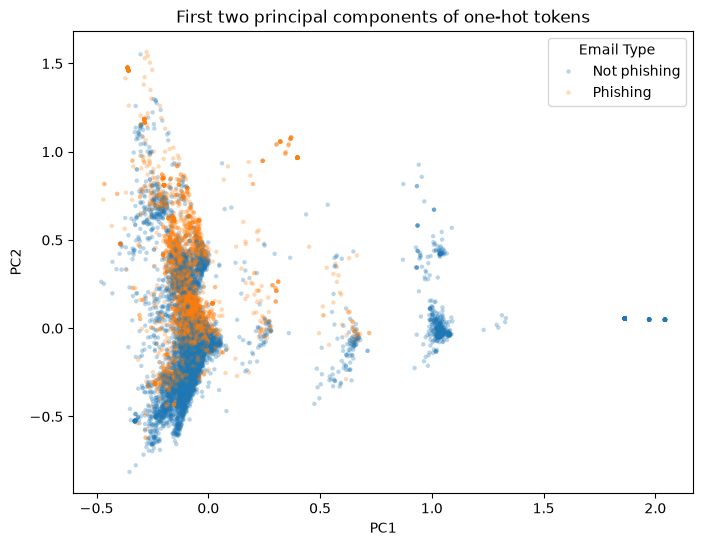

Explained variance ratio: [0.0111 0.0086]


In [37]:
# Q3
from sklearn.decomposition import PCA

pca2 = PCA(n_components=2)
pcs = pca2.fit_transform(X)

pc_df = pd.DataFrame({
    "PC1": pcs[:, 0],
    "PC2": pcs[:, 1],
    "Email Type": y.map({1: "Phishing", 0: "Not phishing"}).to_numpy(),
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pc_df, x="PC1", y="PC2", hue="Email Type",
                s=10, alpha=0.3, linewidth=0)
plt.title("First two principal components of one-hot tokens")
plt.show()

print("Explained variance ratio:", pca2.explained_variance_ratio_.round(4))

Q3. Most emails fall into one dense cluster at the left of the plot (PC1 between about −0.4 and 0.1), where the phishing and non-phishing emails overlap heavily. Within that cluster there’s a loose split: phishing emails tend to sit higher on PC2, and legitimate emails gather toward the bottom. Farther right, there are a few distinct vertical bands around PC1 ≈ 0.6 and PC1 ≈ 1.0, plus a handful of points near 2.0. These are almost entirely non-phishing. They may be groups of similar, templated emails like newsletters that share many of the same tokens. There’s also a small, tight group of phishing emails around PC1 ≈ 0.3, PC2 ≈ 1.0. Overall, the first two components show some real structure, especially high PC1 pointing to legitimate emails, but there’s still a lot of overlap. PC1 and PC2 explain only about 1.1% and 0.9% of the variance in the tokens, around 2% combined. That’s a big reason why the two classes overlap so much in this plot.

In [38]:
# Q4
# Fit PCA on the training data only, then apply it to the test data (avoids leakage)
pca_big = PCA(n_components=2610)
Z_train = pca_big.fit_transform(X_train)
Z_test = pca_big.transform(X_test)

print("Variance retained by 2,610 components:",
      round(pca_big.explained_variance_ratio_.sum(), 4))

reg_pca = LinearRegression().fit(Z_train, y_train)

print("R-squared (train):", round(reg_pca.score(Z_train, y_train), 4))
print("R-squared (test): ", round(reg_pca.score(Z_test, y_test), 4))

Variance retained by 2,610 components: 0.9998
R-squared (train): 0.7651
R-squared (test):  0.6718


Q4. I fit PCA on the training set only and then applied it to the test set, so no information from the test emails leaks into the model. Regressing on the first 2,610 principal components gives an R² of 0.765 on the training set and 0.672 on the test set. That’s nearly identical to the original regression (0.766 train, 0.670 test).

This is expected. Using all 2,711 components would reproduce the original fit exactly, since PCA just rotates the data. Dropping components can’t raise the training R². Here, 2,610 components keep about 99.98% of the variance in the tokens, and cutting the last 100(ish) directions (about 4% of the features) barely changed the fit. So those directions held very little useful information for predicting phishing. The tiny 0.002 change in test R² comes from a single split and is within noise, so it doesn’t really show one model is better than the other.

Q5. With around 2,700 token columns, many words tend to appear together, and many are pretty rare. This makes the original regression unstable: coefficients can get really large or flip signs just to fit noise, like we saw with the HTML tokens in Q2. Principal components fix this by combining the tokens into uncorrelated features, ranked by how much variation they capture. Regressing on them gets rid of the multicollinearity problem. We can also drop the lowest-variance components, so the model has fewer parameters to estimate. One caveat: PCA ranks components by variance in the tokens without looking at whether an email is phishing, so low-variance components aren’t guaranteed to be useless for prediction. Here, though, Q4 showed that dropping them cost us nothing. The tradeoff is interpretability: each component is a mix of many words, so it’s harder to say what any one coefficient means.

### *Reflection on AI assistance
In your own words without generative AI.

The AI review led to several real improvements. I moved all written answers into markdown cells and re-ran the notebook top to bottom so every output is current. In Q1, I added the share of tokens appearing only once (about 60%) and fixed my last sentence, which had compared total token occurrences to the Q2 cutoff, a count of emails containing a token. In Q2, I added the class balance (7,312 phishing vs. 11,322 not) and noted that the coefficients are comparable because every feature is 0/1. In Q3, I reported that PC1 and PC2 explain only about 2% of the variance, which best explains the overlap. In Q4, I removed my claim of “less overfitting,” since a 0.002 test gain from one split is just noise.

The AI also had limitations. It suggested a Zipf-style log–log plot, which goes beyond what the question asked. Its Q4 reasoning that uncorrelated features explain the benefit was off, since rotating the features doesn’t change OLS predictions. It also wasn’t aware that some of its suggestions depended on cell layout: value_counts() didn’t display until I wrapped it in print().

To verify, I restarted the kernel, ran everything, and checked each claim against the printed output: the shapes, the R² values, the explained variance (0.0111 and 0.0086), and the retained variance (99.98%). I also re-checked my Q3 description against the updated plot.

Some concerns remain. All results come from a single random split, the linear probability model can predict outside [0, 1], and the HTML-fragment tokens make the coefficients hard to interpret.